# M5 - Convection and correlations

**Tutoring track, 057922 Nuclear Design and Technology** · Politecnico di Milano

Author: Giovanni Zullo

Run the cells in order, or **Runtime > Run all**.

---

## Contents

1. Newton's cooling law, and what $h$ actually is
2. The dimensionless groups
3. Equivalent diameter
4. Forced convection: Dittus-Boelter
5. Natural convection: McAdams
6. From $h$ to $U$ in cylindrical geometry
7. Uncertainty, carrying it through
8. Exercises


---
## 1. Newton's cooling law, and what $h$ actually is

$$q'' = h_s\,(T_s - T_f)$$

This looks like a physical law. It is closer to a **definition of $h_s$**: it says that
whatever complicated thing the boundary layer is doing, we will summarise it with one
number, defined so that this equation holds.

Three consequences worth taking seriously:

- $h_s$ is **not a property of the fluid**. It depends on the flow, the geometry, the
  surface, and the temperature difference itself.
- $h_s$ is **not measured directly**: it is inferred from correlations fitted to
  experiments. It therefore carries the scatter of those experiments.
- $T_f$ must be defined. For internal flow it is the **bulk** temperature (the velocity-weighted average),
  not the temperature at the channel centreline.

Order of magnitude, in W/(m² K), from Todreas and Kazimi (Vol. I, Table 10.2):

| Situation | $h_s$ |
|---|---|
| Water, forced convection in pipes | 250-12 000 (2500-50 000 with boiling) |
| Low-pressure gas, forced | 6-600 |
| Liquids, natural convection | 60-600 |

The last row is the one to remember: **natural convection is one to two orders of
magnitude weaker than forced convection**; §5 gets about 1070 W/(m² K) for a vessel wall in still water, against about 17 000 in §4. Whenever a design relies on natural
circulation, that gap is the reason it needs large surfaces.


![A heated wall with the fluid above it: the velocity profile drawn as arrows, the temperature profile as a curve, the tangent to that curve at the wall, and three temperature levels marked along the top (wall, bulk and centreline), with the temperature falling from the wall into the fluid.](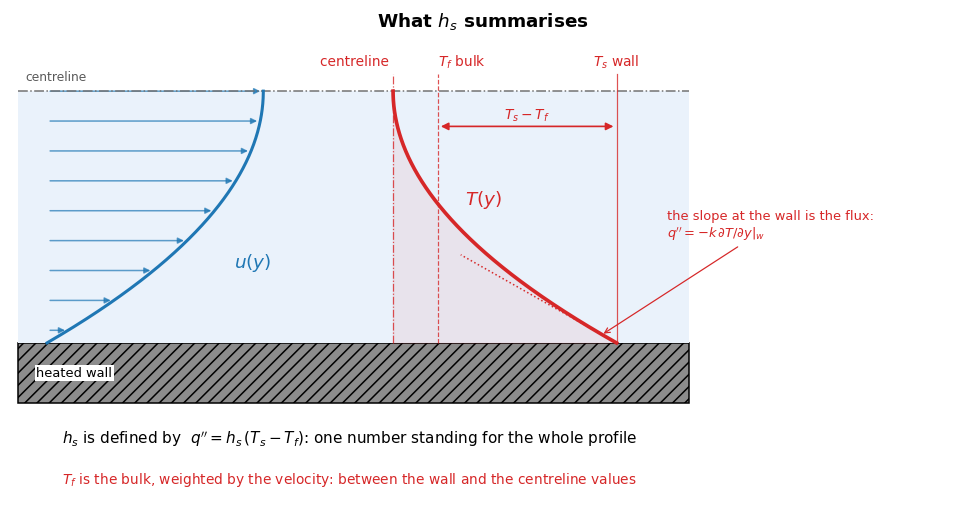)

*What the single number $h_s$ stands for. Velocity is drawn with arrows because it is a vector and temperature as a curve because it is not. The flux leaving the wall is conduction into the fluid, $q'' = -k\,\partial T/\partial y|_w$, the slope of the red curve where it meets the wall; $h_s$ is then whatever number makes $q'' = h_s(T_s - T_f)$ true. Note the top margin: $T_f$ is the **bulk**, an average weighted by the velocity, and it lies between the wall and the centreline values. Using $T_c$ in place of $T_f$ is the commonest way to get $h_s$ wrong. Drawn by `figures/make_figures.py`.*


---
## 2. The dimensionless groups

Here $\eta$ is the dynamic viscosity; Todreas and Kazimi write it $\mu$, which here stays for the attenuation coefficient of gamma rays (§7).

| Group | Definition | Meaning |
|---|---|---|
| Reynolds | $Re = \dfrac{\rho\,\bar u_z D_e}{\eta}$ | inertial / viscous forces: sets the flow regime |
| Prandtl | $Pr = \dfrac{c_p \eta}{k}$ | momentum / thermal diffusivity: a **fluid property** |
| Nusselt | $Nu = \dfrac{h_s D_e}{k}$ | convective / conductive transfer: what correlations predict |
| Grashof | $Gr = \dfrac{\rho^2 g \beta L^3 (T_s-T_f)}{\eta^2}$ | buoyancy / viscous: the $Re$ of natural convection |
| Rayleigh | $Ra = Gr\cdot Pr$ | governs the onset and strength of natural convection |
| Richardson | $Ri = Gr/Re^2$ | which mechanism dominates |

**How they compose.** The chain is always the same, and it is worth carrying as a shape
rather than as a set of formulas:

$$\text{geometry} \rightarrow D_e \quad\text{and}\quad \text{flow + fluid}
\rightarrow Re,\,Pr \;\Longrightarrow\; Nu = f(Re, Pr) \;\Longrightarrow\;
h = \frac{Nu\,k}{D_e}$$

Everything after that is choosing the right correlation and checking you are allowed to
use it.

Two remarks that pay off later.

**$Pr$ separates the coolant families.** Water has $Pr \sim 1$, so momentum and heat
diffuse at comparable rates and the thermal and velocity boundary layers have similar
thickness: this is why Reynolds' analogy works and why $Nu \propto Re^{0.8}Pr^{0.4}$
correlations do so well. Liquid metals have $Pr \sim 10^{-2}$: heat diffuses far faster
than momentum, the analogy collapses, and correlations are written in terms of the
Péclet number $Pe = Re\,Pr$ instead.

**$Ri$ tells you which regime you are in.** $Ri \gg 1$ natural, $Ri \approx 1$ mixed,
$Ri \ll 1$ forced. Mixed convection is the awkward case: neither family of correlations
is strictly valid.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.figsize': (7, 4.2), 'axes.grid': True,
                     'grid.alpha': 0.3, 'font.size': 11})

def reynolds(rho, u, De, eta):      return rho*u*De/eta
def prandtl(cp, eta, k):            return cp*eta/k
def grashof(rho, beta, L, dT, eta, g=9.81):
    return rho**2 * g * beta * L**3 * dT / eta**2

print('helper functions defined')


helper functions defined


---
## 3. Equivalent diameter

Correlations are fitted on circular tubes. Reactor channels are not circular, so we feed
them an **equivalent diameter**

$$D_e = \frac{4A}{P}$$

with $A$ the flow area and $P$ the perimeter. Which perimeter depends on what you are
computing:

- **hydraulic** diameter ($P$ = wetted perimeter) → pressure drop;
- **heated** diameter ($P$ = heated perimeter) → heat transfer in bundles.

In this course we use the hydraulic diameter throughout, which is an acceptable
approximation, but say so when you do it.

| Geometry | $D_e$ |
|---|---|
| Circular pipe, diameter $D$ | $D$ |
| Annulus, $D_o$ and $D_i$ | $D_o - D_i$ |
| Square lattice, pitch $p$, rod $d$ | $d\left[\frac{4}{\pi}\left(\frac{p}{d}\right)^2 - 1\right]$ |
| Triangular lattice | $d\left[\frac{2\sqrt3}{\pi}\left(\frac{p}{d}\right)^2 - 1\right]$ |

The annulus result is worth deriving once by hand: it falls out of
$4A/P$ immediately and is the geometry of the outer downcomer of a vessel.


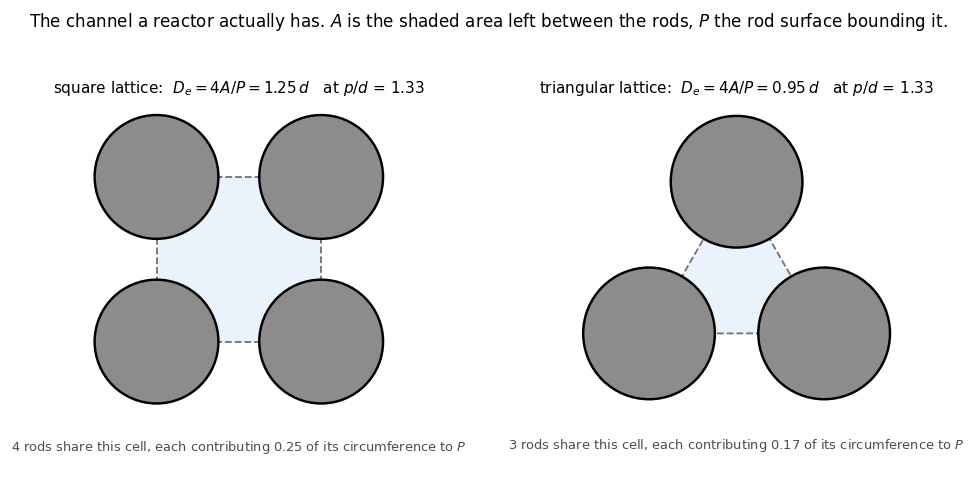

*Where $D_e = 4A/P$ comes from. The shaded region is the flow area $A$ of one cell; the rod surface bounding it is $P$. A rod is shared between neighbouring cells, so each contributes only a fraction of its circumference - a quarter in the square lattice, a sixth in the triangular one. At the same $p/d$ the two lattices give different equivalent diameters, which is why the lattice has to be named before a correlation is used. Drawn by `figures/make_figures.py`.*


In [2]:
def De_circular(D):       return D
def De_annulus(Do, Di):   return Do - Di
def De_square(p, d):      return d*(4/np.pi*(p/d)**2 - 1)
def De_triangular(p, d):  return d*(2*np.sqrt(3)/np.pi*(p/d)**2 - 1)

# check the annulus formula against the definition 4A/P
Do, Di = 0.30, 0.24
A = np.pi/4*(Do**2 - Di**2); P = np.pi*(Do + Di)
print(f'annulus: 4A/P = {4*A/P:.6f} m   vs   Do - Di = {De_annulus(Do,Di):.6f} m')

p, d = 0.0125, 0.0094      # m, a typical PWR-like square lattice
print(f'square lattice  (p/d = {p/d:.3f}): De = {De_square(p,d)*1000:.2f} mm')
print(f'triangular      (p/d = {p/d:.3f}): De = {De_triangular(p,d)*1000:.2f} mm')


annulus: 4A/P = 0.060000 m   vs   Do - Di = 0.060000 m
square lattice  (p/d = 1.330): De = 11.76 mm
triangular      (p/d = 1.330): De = 8.93 mm


---
## 4. Forced convection: Dittus-Boelter

For fully developed turbulent flow,

$$\boxed{\;Nu = 0.023\,Re^{0.8}\,Pr^{\,n}\;}$$

with $n = 0.4$ when the wall **heats** the fluid ($T_s > T_f$) and $n = 0.3$ when it
**cools** it; Todreas and Kazimi, following McAdams, use 0.4 for both. Properties are taken
at the bulk temperature. The asymmetry is not cosmetic: it accounts for how the viscosity of the fluid
changes near the wall, which differs between heating and cooling.

### Validity range, and the habit of checking it

| Source | $Re$ | $Pr$ | $L/D_e$ |
|---|---|---|---|
| Todreas & Kazimi | $> 10^4$ | $0.7-100$ | $> 60$ |
| Bergman et al. (as quoted in the *Notes on Thermo-Hydraulics*, p. 31) | $> 10^4$ | $0.6-160$ | $> 10$ |

Note that two respected sources do not agree on the range. That is normal for an
empirical correlation, and it is a hint about how much precision to claim.

**For rod bundles** a lattice-specific form does better:
$Nu = C\,Pr^{1/3}Re^{0.8}$, with $C = 0.042\,(p/d) - 0.024$ for a square lattice
($1.1 \le p/d \le 1.3$) and $C = 0.026\,(p/d) - 0.006$ for triangular ($1.1 < p/d < 1.5$).

**For liquid metals** Dittus-Boelter does not apply at all: $Pr$ is far below its range.
Use $Nu = \alpha + \beta\,Pe^{\gamma}$ with $Pe = Re\,Pr$ and $\gamma \approx 0.8$.


In [3]:
def dittus_boelter(Re, Pr, heating=True, check=True):
    """Nu = 0.023 Re^0.8 Pr^n. Returns (Nu, warnings)."""
    n  = 0.4 if heating else 0.3
    Nu = 0.023 * Re**0.8 * Pr**n
    w  = []
    if check:
        if Re < 1e4:        w.append(f'Re = {Re:.3g} < 1e4: below the turbulent range')
        if not 0.7 <= Pr <= 100:
            w.append(f'Pr = {Pr:.3g} outside 0.7-100 (Todreas & Kazimi)')
    return Nu, w

def report(name, value, unit, warnings):
    print(f'{name:28s} = {value:12.4g} {unit}')
    for msg in warnings:
        print(f'{"":30s}⚠ {msg}')

# ---- water in an annular downcomer ----
rho_w, eta_w, k_w, cp_w = 800.0, 1.10e-4, 0.620, 4800.0   # water, ~250°C
u_z   = 3.0            # m/s   average axial velocity
De    = De_annulus(0.30, 0.24)

Re = reynolds(rho_w, u_z, De, eta_w)
Pr = prandtl(cp_w, eta_w, k_w)
Nu, warn = dittus_boelter(Re, Pr, heating=True)
h1 = Nu * k_w / De

report('equivalent diameter De', De, 'm', [])
report('Reynolds', Re, '', [])
report('Prandtl',  Pr, '', [])
report('Nusselt (Dittus-Boelter)', Nu, '', warn)
report('h1', h1, 'W/(m2 K)', [])
print('\n   -> above the 250-12 000 W/(m2 K) of water in pipes: the mass flux, rho*u = 2400 kg/(m2 s), is high')


equivalent diameter De       =         0.06 m
Reynolds                     =    1.309e+06 
Prandtl                      =       0.8516 
Nusselt (Dittus-Boelter)     =         1688 
h1                           =    1.744e+04 W/(m2 K)

   -> above the 250-12 000 W/(m2 K) of water in pipes: the mass flux, rho*u = 2400 kg/(m2 s), is high


---
## 5. Natural convection: McAdams

On the outside of a vessel the fluid is nearly stagnant and motion comes from buoyancy
alone. For a vertical wall,

$$\boxed{\;Nu = \frac{h L}{k} = 0.13\,Ra^{1/3}\;}, \qquad Ra = Gr\cdot Pr,
\qquad \text{valid for } 10^{9} < Ra < 10^{12}.$$

Two practical difficulties come with it.

**The correlation needs $\Delta T = T_s - T_f$, which is what you are trying to find.**
The problem is implicit. In practice one either assumes a plausible $\Delta T$ and states
the assumption, or iterates until it is consistent.

**The characteristic length $L$ is the wall height**, and it enters as $L^3$ inside $Gr$.
For a vessel several metres tall, $Ra$ becomes enormous - easily $10^{14}$, i.e., **two
orders of magnitude above the stated validity limit**. Note the saving grace: since
$Nu \propto Ra^{1/3}$ and $Ra \propto L^3$, the $L$ cancels and $h$ is independent of
height. That is what makes the extrapolation defensible, but it is an extrapolation,
and an honest report says so.


In [4]:
def mcadams(Ra, check=True):
    """Nu = 0.13 Ra^(1/3), vertical wall, natural convection."""
    Nu = 0.13 * Ra**(1/3)
    w = []
    if check and not (1e9 <= Ra <= 1e12):
        w.append(f'Ra = {Ra:.3g} OUTSIDE the stated range 1e9-1e12')
    return Nu, w

# ---- stagnant water outside a vessel ----
rho_c, eta_c, k_c, cp_c, beta_c = 983.0, 4.50e-4, 0.650, 4180.0, 5.0e-4
L_wall = 5.0        # m   wall height, the characteristic length
dT_out = 30.0       # K   ASSUMED surface-to-bulk difference

Gr = grashof(rho_c, beta_c, L_wall, dT_out, eta_c)
Pr_c = prandtl(cp_c, eta_c, k_c)
Ra = Gr * Pr_c
Nu_n, warn_n = mcadams(Ra)
h2 = Nu_n * k_c / L_wall

report('Grashof', Gr, '', [])
report('Prandtl (cold water)', Pr_c, '', [])
report('Rayleigh', Ra, '', [])
report('Nusselt (McAdams)', Nu_n, '', warn_n)
report('h2', h2, 'W/(m2 K)', [])

# the L-independence, demonstrated rather than asserted
print('\nh2 as the wall height changes:')
for L in [2.0, 5.0, 10.0]:
    Ra_L = grashof(rho_c, beta_c, L, dT_out, eta_c) * Pr_c
    print(f'   L = {L:4.1f} m ->  Ra = {Ra_L:.3g},  h2 = {mcadams(Ra_L, check=False)[0]*k_c/L:.3f} W/(m2 K)')
print('   -> h2 does not depend on L: Ra ~ L^3 and Nu ~ Ra^(1/3) cancel exactly.')


Grashof                      =    8.777e+13 
Prandtl (cold water)         =        2.894 
Rayleigh                     =     2.54e+14 
Nusselt (McAdams)            =         8233 
                              ⚠ Ra = 2.54e+14 OUTSIDE the stated range 1e9-1e12
h2                           =         1070 W/(m2 K)

h2 as the wall height changes:
   L =  2.0 m ->  Ra = 1.63e+13,  h2 = 1070.276 W/(m2 K)
   L =  5.0 m ->  Ra = 2.54e+14,  h2 = 1070.276 W/(m2 K)
   L = 10.0 m ->  Ra = 2.03e+15,  h2 = 1070.276 W/(m2 K)
   -> h2 does not depend on L: Ra ~ L^3 and Nu ~ Ra^(1/3) cancel exactly.


This is the moment to stop and look at the warning above rather than scroll past it.

The Rayleigh number came out around $10^{14}$, well outside the $10^{9}$-$10^{12}$ window
McAdams is stated for. You have three honest options, and exactly one dishonest one:

1. use it anyway and **say in the report that you extrapolated**, with the argument about
   $L$ cancelling as justification;
2. find a correlation validated at higher $Ra$;
3. bound the answer: show the conclusion does not change over a plausible range of $h_2$.

The dishonest option is to print the number and not mention the range. Note from §6 that
$h_2$ turns out to contribute very little to the overall resistance here, which is what
makes option 3 attractive: if the answer barely depends on $h_2$, its uncertainty does
not matter much, but you have to *show* that, not hope for it.


---
## 6. From $h$ to $U$ in cylindrical geometry

On the outer face of an insulated wall the boundary condition is often a single coefficient
$U_2$, lumping the insulation and the outer film. In cylindrical geometry, **referred to the
outer vessel surface** $2\pi r_{o,v}L$,

$$U_2 = \left[\underbrace{\frac{r_{o,v}}{k_{\text{ins}}}
\ln\!\frac{r_{o,v}+t_{\text{ins}}}{r_{o,v}}}_{\text{conduction, insulation}}
+ \underbrace{\frac{r_{o,v}}{h_2\,(r_{o,v}+t_{\text{ins}})}}_{\text{outer convection}}
\right]^{-1}$$

The factors $r_{o,v}$ and $r_{o,v}/(r_{o,v}+t_{\text{ins}})$ are the
area-ratio corrections of a cylindrical stack: each resistance is being rescaled to the chosen
reference surface. If you drop them you are silently assuming plane geometry.


In [5]:
def U_outer(r_ov, t_ins, k_ins, h2):
    """Overall outer coefficient, cylindrical, referred to the OUTER VESSEL surface."""
    R_cond = r_ov/k_ins * np.log((r_ov + t_ins)/r_ov)
    R_conv = r_ov/(h2*(r_ov + t_ins))
    return 1.0/(R_cond + R_conv), R_cond, R_conv

r_ov, t_ins, k_ins = 0.70, 0.04, 0.85     # m, m, W/(m K)
U2, R_cond, R_conv = U_outer(r_ov, t_ins, k_ins, h2)

print(f'insulation resistance : {R_cond:.5f} m2 K/W   ({100*R_cond/(R_cond+R_conv):.1f} %)')
print(f'outer film resistance : {R_conv:.5f} m2 K/W   ({100*R_conv/(R_cond+R_conv):.1f} %)')
print(f'U2 (referred to r_ov) : {U2:.2f} W/(m2 K)')
print(f'\nCompare with h1 = {h1:.0f} W/(m2 K): the inner film is ~{h1/U2:.0f}x less resistive.')
print('The outer side dominates the thermal resistance of the whole stack.')


insulation resistance : 0.04576 m2 K/W   (98.1 %)
outer film resistance : 0.00088 m2 K/W   (1.9 %)
U2 (referred to r_ov) : 21.44 W/(m2 K)

Compare with h1 = 17444 W/(m2 K): the inner film is ~814x less resistive.
The outer side dominates the thermal resistance of the whole stack.


---
## 7. Uncertainty, carrying it through

Correlations for turbulent forced convection in water carry roughly
$\Delta h/h \approx \pm 20\%$ to $\pm 25\%$, and more for rod bundles, liquid metals,
or anything near boiling. Overestimating $h$ is **non-conservative** for cladding and
wall temperatures, which is why safety margins carry it explicitly.

But a percentage on $h$ is not the interesting number. What matters is the percentage on
**the quantity you are designing against**. Those are not the same, and the difference is
usually favourable, as the calculation below shows on a gamma-heated plane wall.

The wall: steel, $t = 100$ mm, $k = 20$ W/(m K), heated by gamma rays with
$q'''(x) = q_0 e^{-\mu x}$, $q_0 = 2$ MW/m³, where $\mu = 25$ m$^{-1}$ is the attenuation
coefficient. Water at 300°C cools the inner face through the $h_1$ of §4; the outer face
loses heat to 50°C through the $U_2$ of §6. From $k\,T'' + q''' = 0$,
$T(x) = -\dfrac{q_0}{k\mu^2}e^{-\mu x} + C_1x + C_2$, and the two convective conditions fix
$C_1$ and $C_2$.


In [6]:
def wall_solution(k, t, mu, q0, h1, T1, U2, T2):
    """Plane wall, source q0*exp(-mu x) with mu the attenuation coefficient, convection on both faces."""
    a, Et = q0/(k*mu**2), np.exp(-mu*t)
    M   = np.array([[k, -h1], [U2*t + k, U2]])
    rhs = np.array([-h1*T1 - h1*a - q0/mu, U2*a*Et + U2*T2 - q0*Et/mu])
    C1, C2 = np.linalg.solve(M, rhs)
    return lambda x: -a*np.exp(-mu*x) + C1*x + C2

k_s, t_s, mu_s, q0_s = 20.0, 0.10, 25.0, 2.0e6      # steel wall: k (W/(m K)), t (m), mu (1/m), q0 (W/m3)
T_in, T_out = 300.0, 50.0
xs = np.linspace(0, t_s, 1001)

def Tmax_for(h1_, U2_):
    return wall_solution(k_s, t_s, mu_s, q0_s, h1_, T_in, U2_, T_out)(xs).max()

base = Tmax_for(h1, U2)          # reference case, computed first
print(f'reference: T_max = {base:.2f}°C\n')

print('effect of a ±25% error on h1 (inner film):')
for f in [0.75, 1.00, 1.25]:
    Tm = Tmax_for(h1*f, U2)
    print(f'   h1 x {f:.2f}  ->  T_max = {Tm:7.2f}°C   ({Tm-base:+5.2f} K)')

print('\neffect of ±25% on U2 (outer side; U2 is 98% insulation, so this is the insulation conductivity):')
for f in [0.75, 1.00, 1.25]:
    Tm = Tmax_for(h1, U2*f)
    print(f'   U2 x {f:.2f}  ->  T_max = {Tm:7.2f}°C   ({Tm-base:+5.2f} K)')


reference: T_max = 388.09°C

effect of a ±25% error on h1 (inner film):
   h1 x 0.75  ->  T_max =  389.27°C   (+1.18 K)
   h1 x 1.00  ->  T_max =  388.09°C   (+0.00 K)
   h1 x 1.25  ->  T_max =  387.38°C   (-0.71 K)

effect of ±25% on U2 (outer side; U2 is 98% insulation, so this is the insulation conductivity):
   U2 x 0.75  ->  T_max =  394.20°C   (+6.11 K)
   U2 x 1.00  ->  T_max =  388.09°C   (+0.00 K)
   U2 x 1.25  ->  T_max =  382.64°C   (-5.45 K)


Read the two blocks against each other. A $\pm25\%$ uncertainty on $h_1$ barely moves the
peak wall temperature, while the same relative uncertainty on $U_2$ moves it five to eight times as much.

The reason is §6: the inner film contributes almost nothing to the total thermal
resistance, so the answer is insensitive to it, while the outer side dominates. **The
sensitivity follows the resistance, not the error bar of the correlation.**

This is worth generalising. Before agonising over which correlation to use, ask which
resistance dominates. Effort spent refining a term that carries 2% of the total is effort
wasted; effort spent on the term carrying 90% is where the engineering is.


---
## 8. Exercises

**E1 - Annulus by hand.** Derive $D_e = D_o - D_i$ for an annular channel from
$D_e = 4A/P$. Then compute $D_e$ for the square lattice with $p = 12.5$ mm,
$d = 9.4$ mm and check against §3.

**E2 - Heating or cooling?** Redo the $h_1$ of §4 with $n = 0.3$ instead of $0.4$. How
large is the difference, and which exponent is correct for a wall that is *hotter* than
its coolant?

**E3 - The implicit problem.** $h_2$ needs $\Delta T = T_s - T_f$, which depends on
$h_2$. Starting from a guess of $\Delta T = 30$ K, compute $h_2$, use it to obtain a new
$\Delta T$ from the wall solution, and iterate. Does it converge? How many iterations?

**E4 - Which resistance rules.** For the stack of §6, compute what fraction of the total
resistance each layer carries. Then state, in one sentence, which single material
property you would want measured most accurately, and why.

**E5 - Out of range.** Find the wall height $L$ at which $Ra$ would fall inside
McAdams' stated window. Is that a realistic vessel? Write the two sentences you would
put in a report to justify using the correlation anyway.

**E6 - Liquid metal.** For a sodium-cooled channel ($Pr \approx 0.005$), show that
Dittus-Boelter is outside its validity range, and explain physically why a $Pr^{0.4}$
dependence cannot be right when heat diffuses far faster than momentum.
